# BVE: Kinematic Interpolants on LAGRANTO parcel tracks

Explicit version of the ocean notebook (`ki/notebooks/oceans_currents_interpolant.ipynb`) for air parcels of our stochastically stirred barotropic jet. Same two networks (acceleration and velocity score: ReLU MLPs with polynomial and Fourier features of time), same rotating-noise construction, Adam and EMA. What changes: the parcels have identities (LAGRANTO tracks), so the mean path is each parcel's own track and the target is its true acceleration; the split is by parcel (70 % training, 10 % validation, 20 % test) inside one compact patch released together, as in the ocean data. The model sees the window 24-120 h after release; the tests cut a random segment out of every test parcel's track and fill it, forecast after the window and backcast before it, and repeat all three in flows the model never saw. Run in order in the `kinematic_interpolants` kernel; one patch takes about 3 min on an A100.

## 1. Imports

In [1]:
from pathlib import Path
from types import SimpleNamespace
from copy import deepcopy
import json, time
import numpy as np
import torch
from torch import nn
import xarray as xr
import matplotlib.pyplot as plt
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts/ki_tracks.py').is_file())

## 2. Editable hyperparameters
One patch of window 0 by default; set `PATCHES = list(range(8))` for all eight.

In [2]:
BVE_RUN = ROOT / 'data/bve_stirred_jet.nc'
TRACKS = ROOT / 'data/tracks_lagranto_w0.npz'
PATCHES = [0]
T_START_H, T_END_H = 24.0, 120.0   # training window, hours after release
TRAIN_STEPS = 20000
BATCH_SIZE = 1024
WIDTH = 512
DEPTH = 4
FREQS = [2.0**k for k in range(int(np.log2((T_END_H - T_START_H) / 6)) + 1)]  # Fourier periods down to 6 h
LEARNING_RATE = 1e-3
EMA_DECAY = 0.99
TRAIN_NOISE = 1.0
DELTA_H = 6.0   # time scale of the rotating noise
SCORE_LOSS_WEIGHT = 1.0
GAPS_H = [6, 12, 24, 48]
HORIZONS_H = [6, 12, 24]   # forecast and backcast
STEPS_PER_HOUR = 6
UNSEEN = {'trained flow, other patch': (TRACKS, 1),
          'new perturbation': (ROOT / 'data/tracks_lagranto_seed2_w0.npz', 0),
          'new jet and perturbation': (ROOT / 'data/tracks_lagranto_jet40n_w0.npz', 0)}
RUNS = {'trained flow': 'bve_stirred_jet.nc', 'new perturbation': 'bve_seed2.nc', 'new jet and perturbation': 'bve_jet40n.nc'}
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SEED = 0

## 3. The BVE run and the LAGRANTO tracks
Relative vorticity at the release with the eight patch centres; each patch is 1000 parcels in a 300-km disk, advected by LAGRANTO (2-D mode) with the hourly BVE wind.

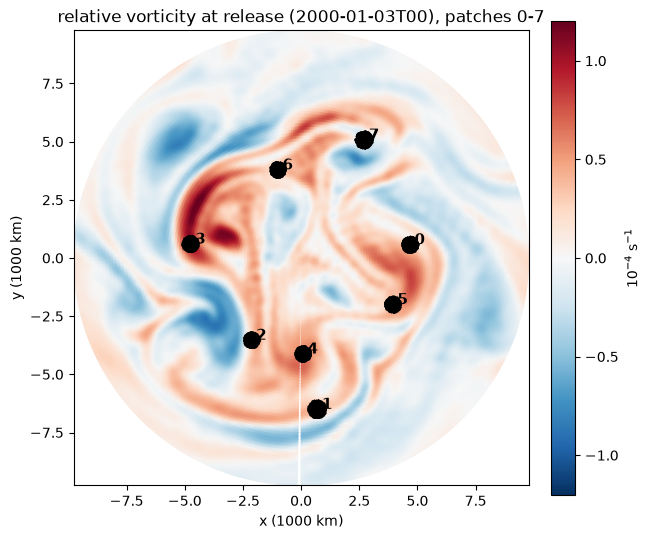

{'x_km': (937, 8000, 2), 'v_kmh': (937, 8000, 2), 'a_kmh2': (937, 8000, 2), 'patch': (8000,), 'split': (8000,)} split counts [5600  800 1600]


In [3]:
def stereo_to_lonlat(x_km):
    """Inverse north-polar stereographic projection (tangent at the pole) -> lon, lat in degrees."""
    r = np.hypot(x_km[..., 0], x_km[..., 1])
    lat = 90.0 - np.rad2deg(2 * np.arctan(r / (2 * 6371.0)))
    lon = np.rad2deg(np.arctan2(x_km[..., 0], -x_km[..., 1])) % 360.0
    return lon, lat


def lonlat_to_stereo(lon, lat):
    """North-polar stereographic projection (tangent at the pole) in km."""
    r = 2 * 6371.0 * np.tan(np.deg2rad(90.0 - lat) / 2)
    lam = np.deg2rad(lon)
    return np.stack([r * np.sin(lam), -r * np.cos(lam)], axis=-1)


def great_circle_km(lon1, lat1, lon2, lat2):
    p1, p2, dl = np.deg2rad(lat1), np.deg2rad(lat2), np.deg2rad(lon2 - lon1)
    c = np.sin(p1) * np.sin(p2) + np.cos(p1) * np.cos(p2) * np.cos(dl)
    return 6371.0 * np.arccos(np.clip(c, -1.0, 1.0))


bve = xr.open_dataset(BVE_RUN)
tracks = np.load(TRACKS)
first = bve.time.values[0] + np.timedelta64(int(round(tracks['start_hour'] + tracks['time_h_abs'][0])), 'h')
z = bve.zeta.sel(time=first, lat=slice(90, 15))
LON, LAT = np.meshgrid(z.lon, z.lat)
XY = lonlat_to_stereo(LON, LAT) / 1e3
fig, ax = plt.subplots(figsize=(6.4, 6), layout='constrained')
pc = ax.pcolormesh(XY[..., 0], XY[..., 1], z * 1e4, cmap='RdBu_r', vmin=-1.2, vmax=1.2, shading='gouraud')
for k in np.unique(tracks['patch']):
    s = tracks['patch'] == k
    xy = tracks['x_km'][0, s] / 1e3
    ax.plot(*xy.T, '.', ms=1, color='k')
    ax.text(*xy.mean(0), f' {k}', fontsize=11, weight='bold')
ax.set_aspect('equal'); ax.set(xlabel='x (1000 km)', ylabel='y (1000 km)', title=f'relative vorticity at release ({str(first)[:13]}), patches 0-7')
fig.colorbar(pc, ax=ax, label='$10^{-4}$ s$^{-1}$', shrink=0.8)
plt.show()
print({k: tracks[k].shape for k in ('x_km', 'v_kmh', 'a_kmh2', 'patch', 'split')}, 'split counts', np.bincount(tracks['split']))

## 4. Acceleration and score networks
The paper's `Field`, with width, depth and time frequencies as arguments (the ocean runs used width 256, depth 2, frequencies 1, 2, 4 per window); `KINet` holds both networks and returns both from one call, which is what DistributedDataParallel needs for multi-GPU training (`scripts/05_train.py`).

In [4]:
OMEGA = np.pi * np.sqrt(3)


class Field(nn.Module):
    """MLP f(t, x, v) with polynomial and Fourier features of t (the paper's Field, sizes and frequencies configurable)."""

    def __init__(self, state_dim=4, width=256, depth=2, freqs=(1, 2, 4), out_dim=2):
        super().__init__()
        self.freqs = tuple(freqs)
        layers = [nn.Linear(4 + 2 * len(self.freqs) + state_dim, width), nn.ReLU()]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), nn.ReLU()]
        self.net = nn.Sequential(*layers, nn.Linear(width, out_dim))
        for layer in self.net[:-1]:
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                nn.init.zeros_(layer.bias)
        nn.init.normal_(self.net[-1].weight, std=0.01)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, t, x, v):
        t = torch.as_tensor(t, dtype=x.dtype, device=x.device).reshape(-1, 1).expand(x.shape[0], 1)
        feats = [torch.ones_like(t), t, t**2, t**3]
        for f in self.freqs:
            feats += [torch.sin(2 * np.pi * f * t), torch.cos(2 * np.pi * f * t)]
        return self.net(torch.cat(feats + [x, v], dim=-1))


class KINet(nn.ModuleList):
    """The acceleration network [0] and the velocity-score network [1]; one forward call returns both (as DDP needs)."""

    def __init__(self, **field_kwargs):
        super().__init__([Field(**field_kwargs), Field(**field_kwargs)])

    def forward(self, t, x, v):
        return self[0](t, x, v), self[1](t, x, v)

## 5. Training minibatches
Positions are centred and scaled by the training parcels, time by the window, exactly as in the ocean notebook. Each sample is a training parcel at a random time, moved off its track by the rotating Gaussian noise; the target acceleration is the true one plus the noise's restoring term.

In [5]:
def load_patch(path, patch, t_end_h, noise=1.0, delta_h=6.0, t_start_h=0.0, center=None, scale=None):
    """Tracks of one patch (patch < 0: all parcels), normalized like the paper on the window [t_start_h, t_end_h].

    Model time is (t - t_start_h) / (t_end_h - t_start_h), so the window is [0, 1]; times before it (backcast) are
    negative and after it (forecast) exceed 1. The training parcels inside the window set the centre and scale
    unless they are given (to apply a trained model to other data).

    Returns a namespace with x, v, a (T, N, 2) inside the window and x_all, v_all, a_all, t_all over the whole
    track, all in model units, the split indices, and the conversion constants (centre, scale in km, clock in h).
    """
    with np.load(path) as f:
        sel = f["patch"] == patch if patch >= 0 else np.ones(len(f["patch"]), bool)
        time_h = f["time_h"]
        keep = (time_h >= t_start_h - 1e-9) & (time_h <= t_end_h + 1e-9)
        X, Vk, Ak = f["x_km"][:, sel], f["v_kmh"][:, sel], f["a_kmh2"][:, sel]
        split = f["split"][sel]
    train, val, test = (np.where(split == s)[0] for s in (0, 1, 2))
    if center is None:
        center = X[keep][:, train].reshape(-1, 2).mean(0)
        scale = float(np.sqrt(((X[keep][:, train] - center) ** 2).mean()))
    clock = float(t_end_h - t_start_h)
    h = delta_h / clock
    sx = noise * h**1.5 / (8 * np.sqrt(3))
    t_all = (time_h - t_start_h) / clock
    return SimpleNamespace(x_all=(X - center) / scale, v_all=Vk * clock / scale, a_all=Ak * clock**2 / scale,
                           t_all=t_all, keep=keep, x=(X[keep] - center) / scale, v=Vk[keep] * clock / scale,
                           a=Ak[keep] * clock**2 / scale, t=t_all[keep], train=train, val=val, test=test,
                           center=np.asarray(center), scale=float(scale), clock=clock, h=h, sx=sx, sv=sx * OMEGA / h)


def training_batch(d, rng, idx, batch, device):
    """States on and around true tracks with their target acceleration and scaled velocity score."""
    i = rng.choice(idx, batch)
    k = rng.integers(len(d.t), size=batch)
    x, v, a = d.x[k, i], d.v[k, i], d.a[k, i]
    z1, z2 = rng.standard_normal((2, batch, 2))
    th = rng.uniform(0.0, 2 * np.pi, (batch, 1))
    par = np.cos(th) * z1 + np.sin(th) * z2
    perp = -np.sin(th) * z1 + np.cos(th) * z2
    arrays = (d.t[k], x + d.sx * par, v + d.sv * perp, a - d.sx * (OMEGA / d.h) ** 2 * par, -perp)
    return tuple(torch.tensor(np.asarray(z), dtype=torch.float32, device=device) for z in arrays)


def batch_loss(model, batch, score_weight=1.0):
    t, x, v, a, q = batch
    a_hat, q_hat = model(t, x, v)
    return ((a_hat - a) ** 2).mean() + score_weight * ((q_hat - q) ** 2).mean()

## 6. Explicit training loop
Adam on acceleration MSE plus score MSE; EMA weights are evaluated on the validation parcels (median error of 24-h gaps) and the best ones are kept.

In [6]:
def integrate(model, d, x0, v0, t0, t1, n_steps, kappa=0.0, seed=0):
    """Heun (deterministic) or Euler-Maruyama (kappa > 0) integration from t0 to t1 (t1 < t0 runs backward).

    t0 and t1 are scalars or per-parcel arrays (N,). Returns positions (n_steps + 1, N, 2) in model units.
    """
    a_net, s_net = model
    gen = torch.Generator(device=x0.device).manual_seed(seed)
    col = lambda t: torch.as_tensor(t, dtype=x0.dtype, device=x0.device).reshape(-1, 1).expand(x0.shape[0], 1)
    t0, t1 = col(t0), col(t1)
    dt = (t1 - t0) / n_steps
    x, v, path = x0.clone(), v0.clone(), [x0.clone()]
    for s in range(n_steps):
        t, tn = t0 + s * dt, t0 + (s + 1) * dt
        if kappa:
            b = a_net(t, x, v) + kappa * s_net(t, x, v) / d.sv
            noise = torch.sqrt(2 * kappa * dt.abs()) * torch.randn(v.shape, generator=gen, device=v.device)
            x, v = x + dt * v, v + dt * b + noise
        else:
            b = a_net(t, x, v)
            xp, vp = x + dt * v, v + dt * b
            x, v = x + 0.5 * dt * (v + vp), v + 0.5 * dt * (b + a_net(tn, xp, vp))
        path.append(x.clone())
    return torch.stack(path)


def infill(model, d, x0, v0, x1, v1, t0, t1, n_steps):
    """Fill a gap: forward from (x0, v0) at t0, backward from (x1, v1) at t1, blended with a smoothstep weight."""
    fwd = integrate(model, d, x0, v0, t0, t1, n_steps)
    bwd = integrate(model, d, x1, v1, t1, t0, n_steps).flip(0)
    u = torch.linspace(0, 1, n_steps + 1, device=x0.device)[:, None, None]
    w = 3 * u**2 - 2 * u**3
    return (1 - w) * fwd + w * bwd


def to_km(d, x_model):
    return np.asarray(x_model) * d.scale + d.center


def gap_errors(net, d, parcels, gap_h, rng, reps=1):
    L, n, out = gap_h / d.clock, int(gap_h * STEPS_PER_HOUR), []
    tt = lambda arr, k: torch.tensor(arr[k, parcels], dtype=torch.float32, device=DEVICE)
    for _ in range(reps):
        k0 = np.searchsorted(d.t, rng.uniform(0, 1 - L, len(parcels)))
        k1 = np.searchsorted(d.t, d.t[k0] + L - 1e-9)
        path = infill(net, d, tt(d.x, k0), tt(d.v, k0), tt(d.x, k1), tt(d.v, k1), d.t[k0], d.t[k1], n).cpu().numpy()
        tq = d.t[k0][None] + (d.t[k1] - d.t[k0])[None] * np.linspace(0, 1, n + 1)[:, None]
        truth = np.stack([np.stack([np.interp(tq[:, j], d.t, d.x[:, q, c]) for c in (0, 1)], -1) for j, q in enumerate(parcels)], 1)
        (lp, ap), (lt, at) = stereo_to_lonlat(to_km(d, path)), stereo_to_lonlat(to_km(d, truth))
        out.append(dict(err=great_circle_km(lp, ap, lt, at), k0=k0, k1=k1, path=path, truth=truth))
    return out


def train_one_fit(d, seed):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = KINet(width=WIDTH, depth=DEPTH, freqs=FREQS).to(DEVICE)
    ema = deepcopy(model).requires_grad_(False)
    opt = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best, best_state, losses, val = np.inf, None, [], []
    for step in range(1, TRAIN_STEPS + 1):
        loss = batch_loss(model, training_batch(d, rng, d.train, BATCH_SIZE, DEVICE), SCORE_LOSS_WEIGHT)
        opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
        with torch.no_grad():
            for e, w in zip(ema.parameters(), model.parameters()):
                e.lerp_(w, 1 - EMA_DECAY)
        if step % 1000 == 0:
            v = float(np.median(gap_errors(ema, d, d.val, 24, np.random.default_rng(1))[0]['err'].mean(0)))
            val.append((step, v))
            if v < best:
                best, best_state = v, deepcopy(ema.state_dict())
            print(f'  {step}/{TRAIN_STEPS}: loss {loss.item():.4g}, validation 24-h gaps median {v:.1f} km', flush=True)
    ema.load_state_dict(best_state)
    return ema.eval(), losses, val


datasets, models, histories = {}, {}, {}
for patch in PATCHES:
    datasets[patch] = load_patch(TRACKS, patch, T_END_H, TRAIN_NOISE, DELTA_H, T_START_H)
    print('Training patch', patch)
    models[patch], *histories[patch] = train_one_fit(datasets[patch], SEED)

Training patch 0


  1000/20000: loss 78.04, validation 24-h gaps median 2.6 km


  2000/20000: loss 73.48, validation 24-h gaps median 2.3 km


  3000/20000: loss 70.76, validation 24-h gaps median 1.9 km


  4000/20000: loss 80.92, validation 24-h gaps median 1.8 km


  5000/20000: loss 79.56, validation 24-h gaps median 1.5 km


... (11 outputs left out)

  17000/20000: loss 73.79, validation 24-h gaps median 1.4 km


  18000/20000: loss 72.54, validation 24-h gaps median 1.3 km


  19000/20000: loss 73.87, validation 24-h gaps median 1.3 km


  20000/20000: loss 74.58, validation 24-h gaps median 1.1 km


## 7. Three abilities: fill, forecast, backcast
Every test parcel loses a random segment of 6, 12, 24 or 48 h inside the training window; the model integrates forward from the segment's start and backward from its end, and the two are blended. The forecast starts every test parcel at the end of the window (120 h after release) and integrates forward; the backcast starts it at the beginning of the window (24 h) and integrates backward, toward the release. `zero acceleration` (straight motion at the known velocities) is the control that shows what training adds.

In [7]:
class Zero(nn.Module):
    def forward(self, t, x, v):
        return torch.zeros_like(x)


zero = nn.ModuleList([Zero(), Zero()])


def abilities(net, d, rng, base):
    rows, ex, pj = [], {}, d.test
    tt = lambda arr, k: torch.tensor(arr[k, pj], dtype=torch.float32, device=DEVICE)
    for gap in GAPS_H:
        res = gap_errors(net, d, pj, gap, rng, reps=3)
        ex[gap] = res[0]
        e = np.concatenate([r['err'].mean(0) for r in res])
        rows.append(dict(base, ability='fill', horizon_h=gap, median_km=np.median(e), p90_km=np.percentile(e, 90)))
    for ability, t0, sign in (('forecast', 1.0, 1), ('backcast', 0.0, -1)):
        k0 = int(np.argmin(np.abs(d.t_all - t0)))
        for h in HORIZONS_H:
            k1 = int(np.argmin(np.abs(d.t_all - (d.t_all[k0] + sign * h / d.clock))))
            end = integrate(net, d, tt(d.x_all, k0), tt(d.v_all, k0), d.t_all[k0], d.t_all[k1], int(h * STEPS_PER_HOUR))[-1].cpu().numpy()
            (lp, ap), (lt, at) = stereo_to_lonlat(to_km(d, end)), stereo_to_lonlat(to_km(d, d.x_all[k1, pj]))
            e = great_circle_km(lp, ap, lt, at)
            rows.append(dict(base, ability=ability, horizon_h=h, median_km=np.median(e), p90_km=np.percentile(e, 90)))
    return rows, ex


rows, examples = [], {}
for patch, d in datasets.items():
    for label, net in (('trained', models[patch]), ('zero acceleration', zero)):
        r, examples[(patch, label)] = abilities(net, d, np.random.default_rng(100 + patch), dict(patch=patch, data='trained flow, same patch', model=label))
        rows += r

## 8. Median errors
Great-circle distance to the true position (averaged along the gap for `fill`; at the end point for `forecast` and `backcast`), median and 90th percentile over the test parcels.

In [8]:
import pandas as pd
summary = pd.DataFrame(rows)
summary.pivot_table(index=['ability', 'horizon_h'], columns='model', values=['median_km', 'p90_km'], aggfunc='median', sort=False).round(1)

median_km                    p90_km                  
model                trained zero acceleration trained zero acceleration
ability  horizon_h                                                      
fill     6               0.5               4.0     0.6              13.8
         12              0.6              12.8     0.8              46.2
         24              1.3              43.1     2.8             129.2
         48              4.3             122.3     9.0             489.2
forecast 6              17.3              55.8    25.7              66.6
         12            116.1             144.5   151.8             209.1
         24            628.9             431.9   859.6             664.2
backcast 6              12.0             124.5    16.2             132.1
         12             50.4             492.3    77.1             519.8
         24            232.7            1790.1   343.5            1904.9

## 9. Visualize
Left: training parcels of the patch (grey) and eight test parcels whose 24-h gap was filled (red dashed = model, blue = truth, black dots = the known ends). Right: error against horizon for the three abilities (solid = trained, dashed = no learning).

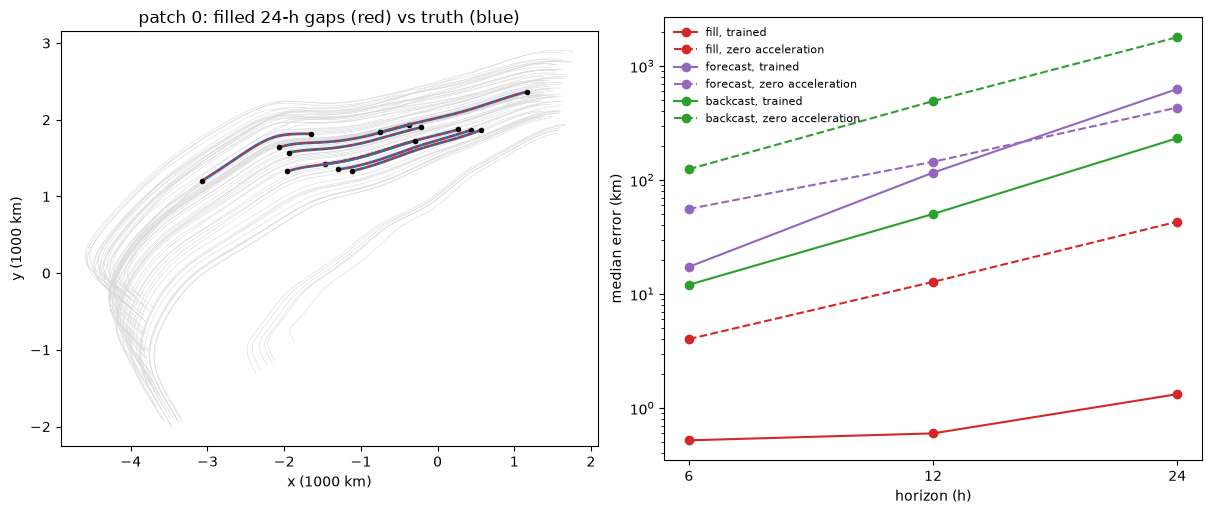

In [9]:
patch = PATCHES[0]; d = datasets[patch]; ex = examples[(patch, 'trained')][24]
fig, ax = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
trk = to_km(d, d.x) / 1e3
ax[0].plot(trk[:, d.train[::10], 0], trk[:, d.train[::10], 1], color='0.85', lw=0.4)
pick = np.argsort(ex['err'].mean(0))[np.linspace(0, len(d.test) - 1, 8).astype(int)]
for j in pick:
    tr, pa = to_km(d, ex['truth'][:, j]) / 1e3, to_km(d, ex['path'][:, j]) / 1e3
    ax[0].plot(*tr.T, color='tab:blue', lw=2); ax[0].plot(*pa.T, color='tab:red', lw=1.2, ls='--')
    ax[0].plot(*tr[[0, -1]].T, 'ko', ms=3)
ax[0].set_aspect('equal'); ax[0].set(xlabel='x (1000 km)', ylabel='y (1000 km)', title=f'patch {patch}: filled 24-h gaps (red) vs truth (blue)')
s = summary[summary.patch == patch]
for ability, color in (('fill', 'tab:red'), ('forecast', 'tab:purple'), ('backcast', 'tab:green')):
    for model, ls in (('trained', '-'), ('zero acceleration', '--')):
        g = s[(s.ability == ability) & (s.model == model) & (s.horizon_h <= 24)]
        ax[1].plot(g.horizon_h, g.median_km, marker='o', ls=ls, color=color, label=f'{ability}, {model}')
ax[1].set(xscale='log', yscale='log', xlabel='horizon (h)', ylabel='median error (km)')
ax[1].xaxis.set_minor_locator(plt.NullLocator()); ax[1].set_xticks(HORIZONS_H, [str(h) for h in HORIZONS_H])
ax[1].legend(frameon=False, fontsize=8)
plt.show()

## 10. Flows the model never saw
The trained model of each patch is applied, with its own centre and scale, to: the next patch of the same flow (another region at the same time); and parcels released at the same positions and time in two other BVE runs, one with the same jet and a new random stirring (new perturbation), one with a 40 m/s jet at 40°N, 8° wide, and a new stirring (new jet and perturbation). Left: the jets (time-mean zonal-mean wind). Right: 24-h errors of the three abilities in each case.

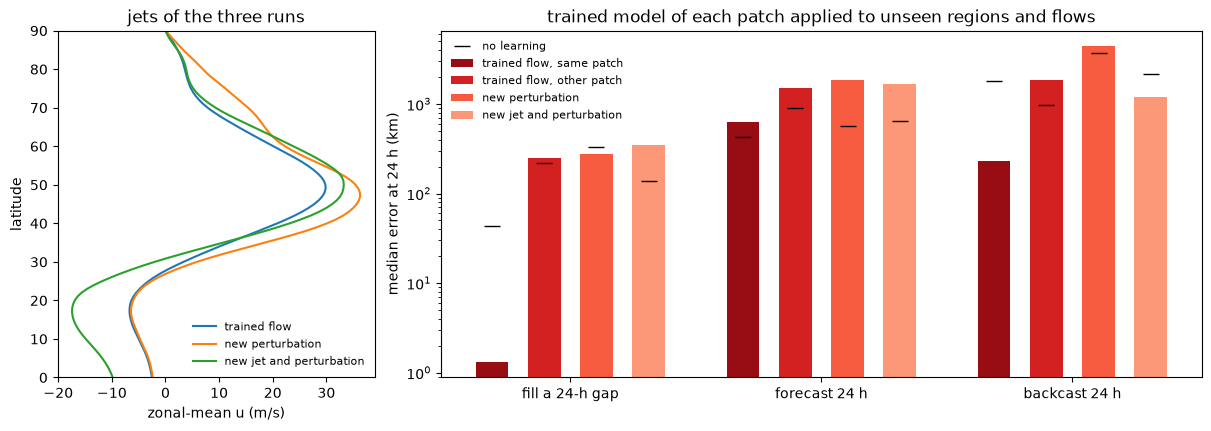

ability                   backcast                      fill  \
model                      trained zero acceleration trained   
data                                                           
new jet and perturbation    1208.4            2184.0   349.1   
new perturbation            4393.1            3681.9   272.9   
trained flow, other patch   1853.7             980.9   250.3   
trained flow, same patch     232.7            1790.1     1.3   

ability                                     forecast                    
model                     zero acceleration  trained zero acceleration  
data                                                                    
new jet and perturbation              136.9   1667.8             642.1  
new perturbation                      326.7   1871.7             570.8  
trained flow, other patch             220.4   1505.1             911.5  
trained flow, same patch               43.1    628.9             431.9

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), layout='constrained', gridspec_kw=dict(width_ratios=[1, 2.4]))
for label, nc in RUNS.items():
    u = xr.open_dataset(ROOT / 'data' / nc).u.mean(('time', 'lon'))
    ax[0].plot(u, u.lat, label=label)
ax[0].set(xlabel='zonal-mean u (m/s)', ylabel='latitude', ylim=(0, 90), title='jets of the three runs')
ax[0].legend(frameon=False, fontsize=8)
for patch in PATCHES:
    ck = dict(center=datasets[patch].center, scale=datasets[patch].scale)
    for label, (path, shift) in UNSEEN.items():
        d_u = load_patch(path, (patch + shift) % 8, T_END_H, TRAIN_NOISE, DELTA_H, T_START_H, **ck)
        for mlabel, net in (('trained', models[patch]), ('zero acceleration', zero)):
            r, _ = abilities(net, d_u, np.random.default_rng(100 + patch), dict(patch=patch, data=label, model=mlabel))
            rows += r
summary = pd.DataFrame(rows)
cases = ['trained flow, same patch', *UNSEEN]
g = summary[(summary.horizon_h == 24)].groupby(['ability', 'data', 'model']).median_km.median()
w = 0.13
for i, ability in enumerate(('fill', 'forecast', 'backcast')):
    for j, case in enumerate(cases):
        ax[1].bar(i + (j - 1.5) * w * 1.6, g.get((ability, case, 'trained'), np.nan), w, color=plt.cm.Reds(0.9 - 0.18 * j), label=case if i == 0 else None)
        ax[1].plot(i + (j - 1.5) * w * 1.6, g.get((ability, case, 'zero acceleration'), np.nan), 'k_', ms=12, label='no learning' if i == 0 and j == 0 else None)
ax[1].set(yscale='log', ylabel='median error at 24 h (km)', title='trained model of each patch applied to unseen regions and flows')
ax[1].set_xticks(range(3), ['fill a 24-h gap', 'forecast 24 h', 'backcast 24 h'])
ax[1].legend(frameon=False, fontsize=8)
plt.show()
summary[summary.horizon_h == 24].pivot_table(index='data', columns=['ability', 'model'], values='median_km', aggfunc='median').round(1)

## 11. Optional export
Set `SAVE = True` to write the summary and the EMA weights.

In [11]:
SAVE = False
if SAVE:
    out = ROOT / 'outputs/notebook'; out.mkdir(parents=True, exist_ok=True)
    summary.to_csv(out / 'summary.csv', index=False)
    for patch, net in models.items():
        torch.save(net.state_dict(), out / f'patch{patch}_s{int(T_START_H)}_t{int(T_END_H)}.pt')